# Star vs Galaxy Classification with XGBoost

**The problem.** Telescopes photograph millions of bright dots in the sky. Each one is a *star* (in our own galaxy), a *galaxy* (far away) or a *quasar* (the extremely bright core of a distant galaxy, which also looks like a dot). Cosmologists need a clean list of galaxies, because stars that sneak into it distort measurements of how galaxies cluster in the universe.

**What we build.** A model that reads each object's catalog measurements (size, shape, brightness, colour) and decides *galaxy or not galaxy*. We use XGBoost, a library that combines many small decision trees into one accurate model. The data are about 2.2 million SDSS DR9 objects that also have a spectrum, and the spectrum tells us the true class.

**How we judge it.** Two numbers, computed separately in each brightness bin:
- **Efficiency**: of all real galaxies, the percentage we kept.
- **Impurity**: of everything we called a galaxy, the percentage that is not a galaxy.

The two trade off, so a fair comparison fixes one and measures the other. The goal is the lowest impurity at the same efficiency as SDSS's own `type` label, the standard rule we want to beat.

**Roadmap.**

| Sections | What happens |
|---|---|
| 1 to 3 | Setup, decisions made up front, loading and cleaning the data |
| 4 to 6 | Looking at the data, building features, splitting into train, validation and test |
| 7 to 9 | Metrics, baselines, and how model scores become a galaxy list |
| 10 to 15 | Training and tuning the model |
| 16 to 21 | Overfitting check and the final test |
| 22 to 27 | Extra checks: quasars, feature importance, amount of data, calibration |
| 28 and 29 | Headline summary and limitations |

## 1. Setup

We import the libraries and set a few constants:
- `SEED = 42` makes every random choice repeatable, so a rerun gives the same numbers.
- `N_TRIALS = 40` is how many settings we try when tuning, and `N_BOOTSTRAP = 1000` is how many resamples we use for error bars (both explained later).
- Brightness bins are one magnitude wide, from 14 to 23. A smaller magnitude means a brighter object.
- If the data file is not in `data/`, this cell downloads it from Hugging Face (about 680 MB).

`DEVICE` tells XGBoost where to train: use `"cpu"` if you have no NVIDIA GPU (slower).

In [ ]:
import time
import urllib.request
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xgboost as xgb
from scipy.stats import loguniform, randint, uniform
from sklearn.calibration import calibration_curve
from sklearn.metrics import log_loss, precision_recall_curve, roc_auc_score
from sklearn.model_selection import ParameterSampler, train_test_split

warnings.filterwarnings("ignore", message=".*Falling back to prediction using DMatrix.*")

SEED = 42
DEVICE = "cuda"
N_TRIALS = 40
N_BOOTSTRAP = 1000

DATA_PATH = Path("data/sdss_dr9_sg.csv")
DATA_URL = "https://huggingface.co/datasets/nevilcp/sdss-dr9-star-galaxy/resolve/main/sdss_dr9_sg.csv"
if not DATA_PATH.exists():
    print(f"Downloading {DATA_URL} (about 680 MB)")
    DATA_PATH.parent.mkdir(parents=True, exist_ok=True)
    partial = DATA_PATH.with_name(DATA_PATH.name + ".part")
    urllib.request.urlretrieve(DATA_URL, partial)
    partial.rename(DATA_PATH)
OUT = Path("outputs")
for folder in ("results", "figures", "models"):
    (OUT / folder).mkdir(parents=True, exist_ok=True)

BIN_EDGES = np.arange(14, 24)
N_BINS = len(BIN_EDGES) - 1
BIN_LABELS = [f"{lo}-{lo + 1}" for lo in BIN_EDGES[:-1]]

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
print("xgboost", xgb.__version__)

xgboost 3.4.1


## 2. Decisions we fix up front

We settle these before looking at any results, so we cannot be tempted to pick whatever looks best afterwards.

| Decision | Choice | Why |
|---|---|---|
| Positive class | **galaxy**. Stars *and* quasars (QSOs) count as "not galaxy" | A galaxy list is what cosmologists want, so anything else in it is contamination |
| Quasars | Kept in the data, then re-checked with them removed (section 22) | They really are contaminants, but this choice changes the numbers, so we show both |
| Main metric | Impurity at fixed efficiency, per `modelmag_r` bin (14 to 23) | Fixing one of the two numbers makes the other comparable. Bins are used because the class mix changes with brightness |
| Efficiency target | Match SDSS `type` in each bin, plus a second target: impurity at most 1% | The first asks "do we beat the standard rule?". The second asks "how many galaxies can we keep at a contamination level a study might accept?" |
| Thresholds | Chosen on the validation set, then frozen. The test set is used once | This keeps the final score honest |

## 3. Load and clean the data

The file holds about 2.2 million SDSS DR9 objects that also have a spectrum. The spectrum gives the trusted answer (`class`: STAR, GALAXY or QSO).

Cleaning steps:
- SDSS stores `-9999` when a value could not be measured. We turn those into missing values (NaN). XGBoost handles missing values natively, so we do not fill them in.
- We drop rows that share the same sky position (`ra`, `dec`), since they are duplicates of one object.
- We add two helper columns: `is_galaxy` (the label to predict) and `mag_bin` (the one-magnitude brightness bin).

The table lists the columns that still have missing values. The shares are small.

In [2]:
raw = pd.read_csv(DATA_PATH).replace(-9999, np.nan)
n_before = len(raw)
raw = raw.drop_duplicates(subset=["ra", "dec"]).reset_index(drop=True)
print(f"rows: {n_before:,} -> {len(raw):,} after dropping duplicate positions")

raw["is_galaxy"] = raw["class"].eq("GALAXY")
raw["mag_bin"] = pd.cut(raw["modelmag_r"], BIN_EDGES, labels=False, include_lowest=True)

missing = raw.isna().mean().mul(100).round(3)
display(missing[missing > 0].sort_values(ascending=False).rename("% missing").to_frame())

rows: 2,195,173 -> 2,195,127 after dropping duplicate positions


,% missing
mrrcc_r,0.030
me1_r,0.030
me2_r,0.030
petror50_r,0.017
petror90_r,0.017
petromag_u,0.002
psfmag_u,0.002
fibermag_u,0.002
modelmag_u,0.002
petromag_z,0.001


## 4. Look at the data

Before modelling, we check how many objects of each class there are and how their brightness is distributed. The mix changes strongly with brightness, which is why we report results per magnitude bin rather than one overall number. The sharp peaks suggest that the spectroscopic sample was *targeted* (objects were chosen for spectra on purpose), so it is not a fair sample of all objects. We return to this in the limitations.

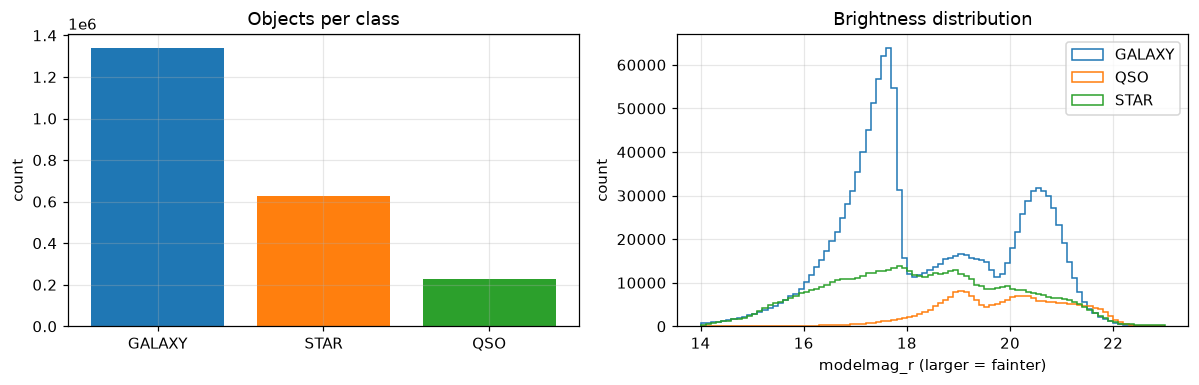

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.6))

counts = raw["class"].value_counts()
ax1.bar(counts.index, counts.values, color=["C0", "C1", "C2"])
ax1.set(title="Objects per class", ylabel="count")

for name, group in raw.groupby("class"):
    ax2.hist(group["modelmag_r"], bins=90, histtype="step", label=name)
ax2.set(title="Brightness distribution", xlabel="modelmag_r (larger = fainter)", ylabel="count")
ax2.legend()
plt.tight_layout()
plt.savefig(OUT / "figures" / "eda_classes_and_magnitudes.png")
plt.show()

## 5. Build the features

A feature is one measurement the model can use. The model sees three kinds of information:
- **Shape**: how big and how round the object looks, and how well star-like or galaxy-like profiles fit it.
- **Magnitudes**: brightness in five colour filters (u, g, r, i, z), measured four ways (fiber, Petrosian, model and PSF).
- **Colours**: differences between neighbouring filters (u-g, g-r, r-i, i-z) for each of the four ways. Stars and galaxies tend to have different colours.

We also add **concentration** (`psfmag_r - modelmag_r`). Stars are point-like, so their point-source and full-model brightness agree, while galaxies are more spread out and the two differ.

This gives 45 features. `type` and `class` are deliberately *not* features: one is the answer and the other is the standard rule we compare against, so using them would be cheating. The `assert` in the code enforces this.

In [4]:
SHAPE = [
    "petror50_r",
    "petror90_r",
    "lnlstar_r",
    "lnlexp_r",
    "lnldev_r",
    "me1_r",
    "me2_r",
    "mrrcc_r",
]
MAG_KINDS = ["fiber", "petro", "model", "psf"]
BANDS = list("ugriz")


def build_features(df):
    feats = df[SHAPE].copy()
    for kind in MAG_KINDS:
        for band in BANDS:
            feats[f"{kind}mag_{band}"] = df[f"{kind}mag_{band}"]
        for lo, hi in zip(BANDS[:-1], BANDS[1:], strict=True):
            feats[f"{kind}_{lo}-{hi}"] = df[f"{kind}mag_{lo}"] - df[f"{kind}mag_{hi}"]
    feats["concentration"] = df["psfmag_r"] - df["modelmag_r"]
    return feats.astype("float32")


X = build_features(raw)
y = raw["is_galaxy"].astype(int)
meta = raw[["class", "type", "is_galaxy", "mag_bin", "modelmag_r"]]

FEATURES = list(X.columns)
FEATURE_GROUPS = {
    "shape": SHAPE,
    "concentration": ["concentration"],
    "magnitudes": [c for c in FEATURES if "mag_" in c],
    "colours": [c for c in FEATURES if "-" in c],
}
assert not {"type", "class"} & set(FEATURES)
print(f"{len(FEATURES)} features:", {k: len(v) for k, v in FEATURE_GROUPS.items()})

45 features: {'shape': 8, 'concentration': 1, 'magnitudes': 20, 'colours': 16}


## 6. Split into train, validation and test

We split the objects into three separate groups, so the model is always scored on objects it has never seen:
- **Train (60%)**: the model learns from these. More training data keeps lowering impurity (see the training-size plot in section 25), so it gets the biggest share.
- **Validation (20%)**: we tune settings, stop training early and choose thresholds here.
- **Test (20%)**: used once at the end for an honest score. The faintest bin has only about 2,600 galaxies in total, so test and validation each keep about 500 of them.

The split is random with a fixed seed. It is also *stratified*: balanced by class and brightness bin, so every set has the same mix (the table shows about 61% galaxies and 10% quasars in each). We save the row numbers so any later run uses the identical split.

In [5]:
strata = raw["class"] + "_" + raw["mag_bin"].astype(str)
dev_idx, test_idx = train_test_split(raw.index, test_size=0.2, stratify=strata, random_state=SEED)
train_idx, val_idx = train_test_split(
    dev_idx, test_size=0.25, stratify=strata[dev_idx], random_state=SEED
)

np.savez(OUT / "results" / "split_indices.npz", train=train_idx, val=val_idx, test=test_idx)

splits = {"train": train_idx, "val": val_idx, "test": test_idx}
summary = pd.DataFrame(
    {
        name: {
            "rows": len(idx),
            "% galaxy": 100 * y[idx].mean(),
            "% QSO": 100 * (raw["class"][idx] == "QSO").mean(),
        }
        for name, idx in splits.items()
    }
).T
display(summary.round(1))

meta_train, meta_val, meta_test = (meta.loc[idx] for idx in splits.values())
y_train, y_val, y_test = (y.loc[idx] for idx in splits.values())

,rows,% galaxy,% QSO
train,1317075.0,61.0,10.4
val,439026.0,61.0,10.4
test,439026.0,61.0,10.4


## 7. Measuring efficiency and impurity

Two small helpers do the counting, so the same definitions are used everywhere:
- `selection_counts` counts, in each brightness bin, how many objects of each class were selected and how many exist.
- `efficiency_impurity` turns those counts into the two percentages.

Efficiency is the share of all real galaxies that were selected. Impurity is the share of selected objects that are not galaxies, so it counts both stars and quasars.

In [6]:
def selection_counts(meta_df, selected):
    selected = np.asarray(selected, dtype=bool)
    total = pd.crosstab(meta_df["mag_bin"], meta_df["class"])
    chosen = pd.crosstab(meta_df["mag_bin"][selected], meta_df["class"][selected])
    chosen = chosen.reindex(index=total.index, columns=total.columns, fill_value=0)
    return pd.concat({"selected": chosen, "total": total}, axis=1)


def efficiency_impurity(counts):
    galaxies_kept = counts[("selected", "GALAXY")]
    all_selected = counts["selected"].sum(axis=1)
    return pd.DataFrame(
        {
            "efficiency": 100 * galaxies_kept / counts[("total", "GALAXY")],
            "impurity": 100 * (all_selected - galaxies_kept) / all_selected,
        }
    )

## 8. Baselines: what we have to beat

A model score means little without something to compare it to. We use two simple rules:
1. **SDSS `type`**: the survey's own label (`type == 3` means galaxy). This is the main target.
2. **A simple cut**: call it a galaxy if `psfmag_r - modelmag_r > 0.145`, a well-known single-feature rule that `type` closely resembles.

We compute their efficiency and impurity per bin on the validation set (used later to set the targets) and on the test set (used for the final comparison). The table shows the test-set numbers: the simple cut stays close to `type` for bright objects but is much worse for faint ones.

In [7]:
def baseline_selections(meta_df, X_df):
    return {
        "SDSS type": meta_df["type"].eq(3).to_numpy(),
        "concentration > 0.145": (X_df["concentration"] > 0.145).to_numpy(),
    }


X_val, X_test = X.loc[val_idx], X.loc[test_idx]

baselines_val = {
    name: efficiency_impurity(selection_counts(meta_val, sel))
    for name, sel in baseline_selections(meta_val, X_val).items()
}
baselines_test = {
    name: efficiency_impurity(selection_counts(meta_test, sel))
    for name, sel in baseline_selections(meta_test, X_test).items()
}

baseline_table = pd.concat(baselines_test, axis=1).round(2)
baseline_table.index = BIN_LABELS
display(baseline_table)

SDSS type          concentration > 0.145         
      efficiency impurity            efficiency impurity
14-15      99.45     3.60                 99.45     4.08
15-16      99.30     3.85                 99.30     4.32
16-17      99.58     2.46                 99.58     2.63
17-18      99.82     1.90                 99.82     2.02
18-19      98.79     5.77                 98.78     6.18
19-20      97.93     4.61                 98.01     5.10
20-21      98.08     5.28                 98.19     5.76
21-22      91.61     8.40                 91.99    14.24
22-23      64.66    32.18                 56.31    49.39

## 9. Turning scores into a galaxy list

XGBoost gives every object a score. A **threshold** then decides which objects are called galaxies: raise it for a purer but smaller list, lower it for a bigger but dirtier one. We pick a separate threshold in each bin, because the best cut-off differs between bright and faint objects.

- `matched_thresholds` sets, in each bin, the threshold that keeps the same share of real galaxies as a target. We use SDSS `type`'s efficiency as the target, so the comparison is fair.
- `impurity_cap_thresholds` instead finds the loosest threshold that still keeps impurity at or below a cap (1%), which keeps as many galaxies as possible. It ignores lists shorter than 50 objects, because impurity on a handful of objects is unreliable.

We use the raw log-odds score (`output_margin`) rather than a probability, because probabilities of almost exactly 1.0 can tie and make thresholds ambiguous.

In [8]:
def matched_thresholds(score, is_galaxy, bins, target_efficiency):
    thresholds = np.empty(N_BINS)
    for b, eff in enumerate(target_efficiency):
        galaxy_scores = score[(bins == b) & is_galaxy]
        thresholds[b] = np.quantile(galaxy_scores, 1 - eff)
    return thresholds


def impurity_cap_thresholds(score, is_galaxy, bins, cap=0.01, min_selected=50):
    thresholds = np.full(N_BINS, np.nan)
    for b in range(N_BINS):
        in_bin = bins == b
        order = np.argsort(-score[in_bin])
        ranked_score = score[in_bin][order]
        contaminants = np.cumsum(~is_galaxy[in_bin][order])
        n_selected = np.arange(1, len(order) + 1)
        allowed = (contaminants / n_selected <= cap) & (n_selected >= min_selected)
        if allowed.any():
            thresholds[b] = ranked_score[np.flatnonzero(allowed)[-1]]
    return thresholds


def select(score, thresholds, bins):
    return score >= thresholds[bins]


bins_val = meta_val["mag_bin"].to_numpy()
bins_test = meta_test["mag_bin"].to_numpy()
gal_val = meta_val["is_galaxy"].to_numpy()
gal_test = meta_test["is_galaxy"].to_numpy()

target_efficiency = baselines_val["SDSS type"]["efficiency"].to_numpy() / 100

## 10. Training helpers

`fit_and_score` trains one XGBoost model and returns its per-bin impurity on the validation set at SDSS-matched efficiency. Every experiment below reuses it.

Key settings, from the XGBoost documentation:
- `tree_method="hist"`: fast histogram-based splits (with `device="cuda"` it runs on the GPU).
- `early_stopping_rounds=50`: training stops once the validation loss has not improved for 50 trees. The best tree count is found automatically, which protects against overfitting.
- `n_estimators=2000` is only an upper limit. Early stopping normally ends training well before it.

Tuning needs a single number to compare models. We use the **geometric mean of impurity across bins** (`typical_impurity`), so bright and faint bins count equally. A plain average would be dominated by the faint bin, where impurity is far larger.

In [9]:
BASE_PARAMS = dict(
    objective="binary:logistic",
    n_estimators=2000,
    tree_method="hist",
    device=DEVICE,
    eval_metric="logloss",
    early_stopping_rounds=50,
)


def typical_impurity(per_bin_impurity):
    return float(np.exp(np.log(np.clip(per_bin_impurity, 1e-3, None)).mean()))


def margin(model, features):
    return model.predict(features, output_margin=True)


def validation_impurity(score):
    thresholds = matched_thresholds(score, gal_val, bins_val, target_efficiency)
    counts = selection_counts(meta_val, select(score, thresholds, bins_val))
    return efficiency_impurity(counts)["impurity"].to_numpy()


def fit_and_score(params, rows, columns=FEATURES, seed=SEED, track_train=False):
    X_tr, y_tr = X.loc[rows, columns], y.loc[rows]
    X_va = X.loc[val_idx, columns]
    eval_set = [(X_va, y_val)] if not track_train else [(X_tr, y_tr), (X_va, y_val)]

    model = xgb.XGBClassifier(**BASE_PARAMS, **params, random_state=seed)
    model.fit(X_tr, y_tr, eval_set=eval_set, verbose=False)
    return model, validation_impurity(margin(model, X_va))

## 11. First model with default settings

Before any tuning we train with XGBoost's default settings. This gives a reference point, so we can tell later whether tuning actually helped. The output also shows the same number for SDSS `type`, so we can already see whether the model beats the standard rule.

In [10]:
default_model, default_impurity = fit_and_score({}, train_idx)
print(f"trees used: {default_model.best_iteration + 1}")
print(f"typical validation impurity: {typical_impurity(default_impurity):.3f}%")
type_impurity = typical_impurity(baselines_val["SDSS type"]["impurity"].to_numpy())
print(f"SDSS type, same bins:        {type_impurity:.3f}%")

trees used: 186
typical validation impurity: 2.525%
SDSS type, same bins:        5.087%


## 12. Tune the settings

Settings such as tree depth are chosen by us, not learned from the data, so we search for good values. We try 40 random combinations of the settings below and keep the ones with the lowest validation impurity. Random search covers the space better than a grid for the same effort.

| Setting | What it controls |
|---|---|
| `max_depth` | how many questions each tree can ask |
| `min_child_weight` | minimum amount of data a leaf needs, which prevents tiny leaves |
| `learning_rate` | how big a step each new tree takes |
| `subsample`, `colsample_bytree` | share of rows and features each tree sees |
| `reg_lambda` | penalty that keeps leaf values small |

The number of trees is not tuned: early stopping picks it. Every trial is scored on the validation set, never on the test set.

In [11]:
search_space = {
    "max_depth": randint(3, 11),
    "min_child_weight": loguniform(1, 100),
    "learning_rate": loguniform(0.03, 0.2),
    "subsample": uniform(0.5, 0.5),
    "colsample_bytree": uniform(0.5, 0.5),
    "reg_lambda": loguniform(0.1, 10),
}
trials = [
    {k: np.asarray(v).item() for k, v in params.items()}
    for params in ParameterSampler(search_space, n_iter=N_TRIALS, random_state=SEED)
]

records = []
for i, params in enumerate(trials, start=1):
    start = time.time()
    model, impurity = fit_and_score(params, train_idx)
    records.append(
        {**params, "trees": model.best_iteration + 1, "impurity": typical_impurity(impurity)}
    )
    if i % 5 == 0:
        print(f"trial {i}/{N_TRIALS}, last took {time.time() - start:.0f}s")

tuning = pd.DataFrame(records).sort_values("impurity").reset_index(drop=True)
tuning.to_csv(OUT / "results" / "tuning_trials.csv", index=False)
display(tuning.head(8).round(3))

trial 5/40, last took 11s


trial 10/40, last took 9s


trial 15/40, last took 14s


trial 20/40, last took 8s


trial 25/40, last took 10s


trial 30/40, last took 16s


trial 35/40, last took 15s


trial 40/40, last took 12s


,colsample_bytree,learning_rate,max_depth,min_child_weight,reg_lambda,subsample,trees,impurity
0,0.554,0.032,9,8.928,1.338,0.848,1134,2.208
1,0.918,0.055,8,24.639,5.209,0.663,975,2.221
2,0.961,0.035,9,11.007,8.363,0.922,1288,2.241
3,0.834,0.090,10,1.596,2.123,0.503,165,2.246
4,0.580,0.085,8,7.886,9.748,0.588,539,2.255
5,0.570,0.094,9,32.442,0.287,0.538,365,2.272
6,0.509,0.077,10,31.116,1.992,0.925,631,2.287
7,0.944,0.073,7,87.786,4.987,0.861,1237,2.292


## 13. Check that the best settings are stable

A configuration can win one trial by luck, because training involves randomness (row and feature sampling). To avoid picking a lucky one, we retrain the top 3 with three different seeds each and pick the one with the best *average*. The `spread` column shows how much the three runs differ.

In [12]:
param_names = list(search_space)
top3 = tuning.head(3)

stability = []
for rank, row in top3.iterrows():
    params = {k: (int(row[k]) if k == "max_depth" else float(row[k])) for k in param_names}
    scores = [typical_impurity(fit_and_score(params, train_idx, seed=s)[1]) for s in (1, 2, 3)]
    stability.append({"rank": rank, "mean": np.mean(scores), "spread": np.ptp(scores), **params})

stability = pd.DataFrame(stability).sort_values("mean").reset_index(drop=True)
display(stability.round(3))

best = stability.iloc[0]
best_params = {k: int(best[k]) if k == "max_depth" else float(best[k]) for k in param_names}
print(best_params)

,rank,mean,spread,max_depth,min_child_weight,learning_rate,subsample,colsample_bytree,reg_lambda
0,0,2.228,0.056,9,8.928,0.032,0.848,0.554,1.338
1,2,2.245,0.026,9,11.007,0.035,0.922,0.961,8.363
2,1,2.269,0.056,8,24.639,0.055,0.663,0.918,5.209


{'max_depth': 9, 'min_child_weight': 8.927717642767776, 'learning_rate': 0.031843150945538586, 'subsample': 0.8477580432130638, 'colsample_bytree': 0.5539457134966522, 'reg_lambda': 1.338292807656262}


## 14. Does the training mix matter?

About 40% of the training set is stars and quasars. Sevilla-Noarbe & Etayo-Sotos (2015) found that a training set needs at least 20% background objects (stars in their case), so the natural mix is already above that. We still test whether reweighting the two classes so they count equally (`scale_pos_weight`) helps or hurts. If it makes no difference, we keep the natural mix, because it is simpler and matches the real data.

In [13]:
ratio = float((y_train == 0).sum() / (y_train == 1).sum())
mix_results = {}
for name, extra in {"natural mix": {}, "balanced weights": {"scale_pos_weight": ratio}}.items():
    _, impurity = fit_and_score({**best_params, **extra}, train_idx)
    mix_results[name] = typical_impurity(impurity)
display(pd.Series(mix_results, name="typical validation impurity (%)").round(3).to_frame())

,typical validation impurity (%)
natural mix,2.208
balanced weights,2.263


## 15. Train the final model

We train once more with the chosen settings, this time also recording the training loss so we can draw a learning curve (loss against number of trees). The dashed line marks the tree count that early stopping chose. Then we save the model to `outputs/models/`.

trees used: 1134


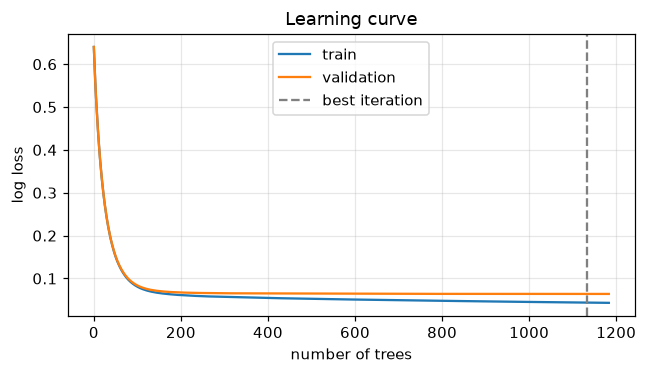

In [14]:
final_model, _ = fit_and_score(best_params, train_idx, track_train=True)
final_model.save_model(OUT / "models" / "xgb_final.json")
print(f"trees used: {final_model.best_iteration + 1}")

history = final_model.evals_result()
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(history["validation_0"]["logloss"], label="train")
ax.plot(history["validation_1"]["logloss"], label="validation")
ax.axvline(final_model.best_iteration, ls="--", color="gray", label="best iteration")
ax.set(xlabel="number of trees", ylabel="log loss", title="Learning curve")
ax.legend()
plt.tight_layout()
plt.savefig(OUT / "figures" / "learning_curve.png")
plt.show()

## 16. Overfitting check

Overfitting means the model memorised the training data and does worse on new data. We compare scores on all three sets. A small gap between train and validation or test is normal, and a big gap would be a warning.

- **Log loss**: how far the predicted probabilities are from the truth. Lower is better.
- **AUC**: how well the model ranks galaxies above non-galaxies. 1.0 is perfect separation, and 0.5 is a coin flip.

In [15]:
rows = []
for name, features, target in [
    ("train", X.loc[train_idx], y_train),
    ("val", X_val, y_val),
    ("test", X_test, y_test),
]:
    probability = final_model.predict_proba(features)[:, 1]
    rows.append(
        {
            "set": name,
            "log loss": log_loss(target, probability),
            "AUC": roc_auc_score(target, probability),
        }
    )
display(pd.DataFrame(rows).set_index("set").round(4))

,log loss,AUC
set,,
train,0.0437,0.9984
val,0.0640,0.9957
test,0.0644,0.9956


## 17. Freeze the thresholds on the validation set

This is the key step for an honest result. Using validation data only, we compute two sets of thresholds, one per bin:
- **Operating point A**: the threshold that gives the same efficiency as SDSS `type`.
- **Operating point B**: the threshold that keeps impurity at or below 1%.

After this cell the thresholds never change, and the test set plays no part in choosing them. Choosing them on the test set would make the final score look better than it really is.

In [16]:
score_val = margin(final_model, X_val)
thresholds_a = matched_thresholds(score_val, gal_val, bins_val, target_efficiency)
thresholds_b = impurity_cap_thresholds(score_val, gal_val, bins_val, cap=0.01)

thresholds = pd.DataFrame(
    {"A: match SDSS efficiency": thresholds_a, "B: impurity <= 1%": thresholds_b}, index=BIN_LABELS
)
thresholds.to_csv(OUT / "results" / "frozen_thresholds.csv")
display(thresholds.round(3))

,A: match SDSS efficiency,B: impurity <= 1%
14-15,-2.235,-0.445
15-16,-1.908,-1.019
16-17,-1.056,-1.970
17-18,-1.800,-2.642
18-19,-1.256,-0.333
19-20,-0.154,1.716
20-21,0.011,3.939
21-22,0.399,4.292
22-23,0.262,NaN


## 18. Final test: matched efficiency (operating point A)

Now we use the test set, once. We apply the frozen thresholds and compare XGBoost with SDSS `type` bin by bin. Both keep the same share of galaxies, so the lower impurity wins. The ratio columns show how many times lower XGBoost's impurity is.

**Error bars.** We use the *bootstrap*: resample the test objects with replacement 1,000 times and see how much the numbers move. The range between the 16th and 84th percentiles is a 68% confidence interval. Each bin is resampled on its own. The thresholds stay frozen, so their own uncertainty is not included.

In [17]:
GALAXY, XGB_SEL, TYPE_SEL = ((np.arange(8) >> k) & 1 == 1 for k in (2, 1, 0))


def joint_counts(selected_xgb, selected_type):
    code_ = gal_test.astype(int) * 4 + selected_xgb.astype(int) * 2 + selected_type.astype(int)
    table = np.zeros((N_BINS, 8), dtype=np.int64)
    np.add.at(table, (bins_test, code_), 1)
    return table


def rates(table, selector):
    selected = table[..., selector].sum(-1)
    galaxies_kept = table[..., selector & GALAXY].sum(-1)
    efficiency = 100 * galaxies_kept / table[..., GALAXY].sum(-1)
    impurity = 100 * (selected - galaxies_kept) / selected
    return efficiency, impurity


def bootstrap(table, rng):
    probabilities = table / table.sum(axis=1, keepdims=True)
    return np.stack(
        [
            rng.multinomial(table[b].sum(), probabilities[b], size=N_BOOTSTRAP)
            for b in range(N_BINS)
        ],
        axis=1,
    )


score_test = margin(final_model, X_test)
type_selected_test = baseline_selections(meta_test, X_test)["SDSS type"]
selected_a = select(score_test, thresholds_a, bins_test)

table_a = joint_counts(selected_a, type_selected_test)
draws = bootstrap(table_a, np.random.default_rng(SEED))


def comparison_table(table, draws):
    all_bins = np.concatenate([table, table.sum(0, keepdims=True)])
    all_draws = np.concatenate([draws, draws.sum(1, keepdims=True)], axis=1)

    xgb_eff, xgb_imp = rates(all_bins, XGB_SEL)
    type_eff, type_imp = rates(all_bins, TYPE_SEL)
    _, xgb_imp_draws = rates(all_draws, XGB_SEL)
    _, type_imp_draws = rates(all_draws, TYPE_SEL)
    ratio_draws = type_imp_draws / xgb_imp_draws

    low, high = np.nanpercentile(xgb_imp_draws, [16, 84], axis=0)
    ratio_low, ratio_high = np.nanpercentile(ratio_draws, [16, 84], axis=0)
    return pd.DataFrame(
        {
            "type eff %": type_eff,
            "type imp %": type_imp,
            "xgb eff %": xgb_eff,
            "xgb imp %": xgb_imp,
            "xgb imp low": low,
            "xgb imp high": high,
            "type/xgb ratio": type_imp / xgb_imp,
            "ratio low": ratio_low,
            "ratio high": ratio_high,
        },
        index=BIN_LABELS + ["all bins"],
    )


result_a = comparison_table(table_a, draws)
result_a.to_csv(OUT / "results" / "test_matched_efficiency.csv")
display(result_a.round(2))

,type eff %,type imp %,xgb eff %,xgb imp %,xgb imp low,xgb imp high,type/xgb ratio,ratio low,ratio high
14-15,99.45,3.60,99.45,1.88,1.63,2.15,1.91,1.74,2.12
15-16,99.30,3.85,99.31,1.30,1.18,1.40,2.97,2.78,3.22
16-17,99.58,2.46,99.56,0.71,0.67,0.75,3.46,3.28,3.66
17-18,99.82,1.90,99.81,0.81,0.78,0.84,2.34,2.28,2.41
18-19,98.79,5.77,98.78,1.83,1.75,1.91,3.15,3.03,3.28
19-20,97.93,4.61,98.05,1.78,1.70,1.85,2.59,2.49,2.68
20-21,98.08,5.28,98.09,3.16,3.08,3.23,1.67,1.65,1.70
21-22,91.61,8.40,91.78,4.78,4.59,4.96,1.76,1.72,1.81
22-23,64.66,32.18,66.80,19.81,17.95,21.70,1.62,1.51,1.75
all bins,98.60,3.84,98.63,1.74,1.71,1.76,2.21,2.18,2.23


## 19. Plot the main result

Impurity per brightness bin, on a log scale so bright and faint bins are both readable. Lower is better. Black dots are the SDSS `type` rule. The blue line is XGBoost, with its 68% interval. Where the blue line is below the dots, XGBoost wins.

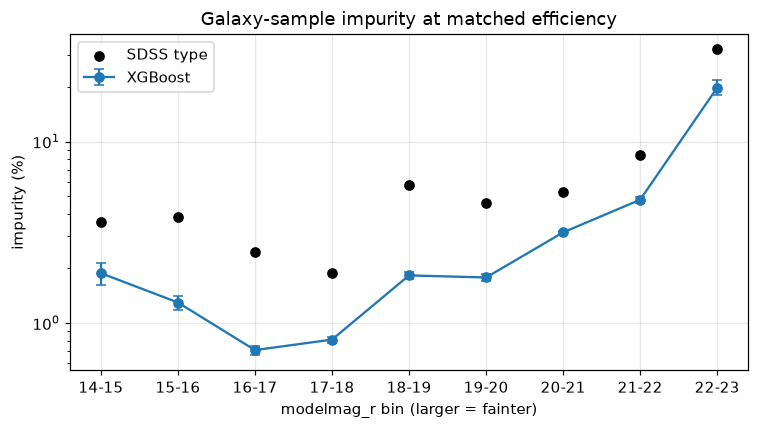

In [18]:
per_bin = result_a.iloc[:-1]
x = np.arange(N_BINS)
yerr = np.vstack(
    [per_bin["xgb imp %"] - per_bin["xgb imp low"], per_bin["xgb imp high"] - per_bin["xgb imp %"]]
)

fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(x, per_bin["xgb imp %"], yerr=yerr, marker="o", color="C0", capsize=3, label="XGBoost")
ax.scatter(x, per_bin["type imp %"], color="black", zorder=3, label="SDSS type")
ax.set(
    yscale="log",
    xlabel="modelmag_r bin (larger = fainter)",
    ylabel="impurity (%)",
    title="Galaxy-sample impurity at matched efficiency",
)
ax.set_xticks(x, BIN_LABELS)
ax.legend()
plt.tight_layout()
plt.savefig(OUT / "figures" / "impurity_vs_type.png")
plt.show()

## 20. The whole trade-off, not just one point

Matching SDSS efficiency is a fair comparison, but it is only one point on a curve. Each panel below shows the full curve for one brightness bin: how much impurity you pay for each efficiency. The blue line is XGBoost, the black dot is where SDSS `type` sits and the red cross is XGBoost at matched efficiency. A curve that stays below the dot means XGBoost is better at that efficiency, so the result does not depend on one flattering point.

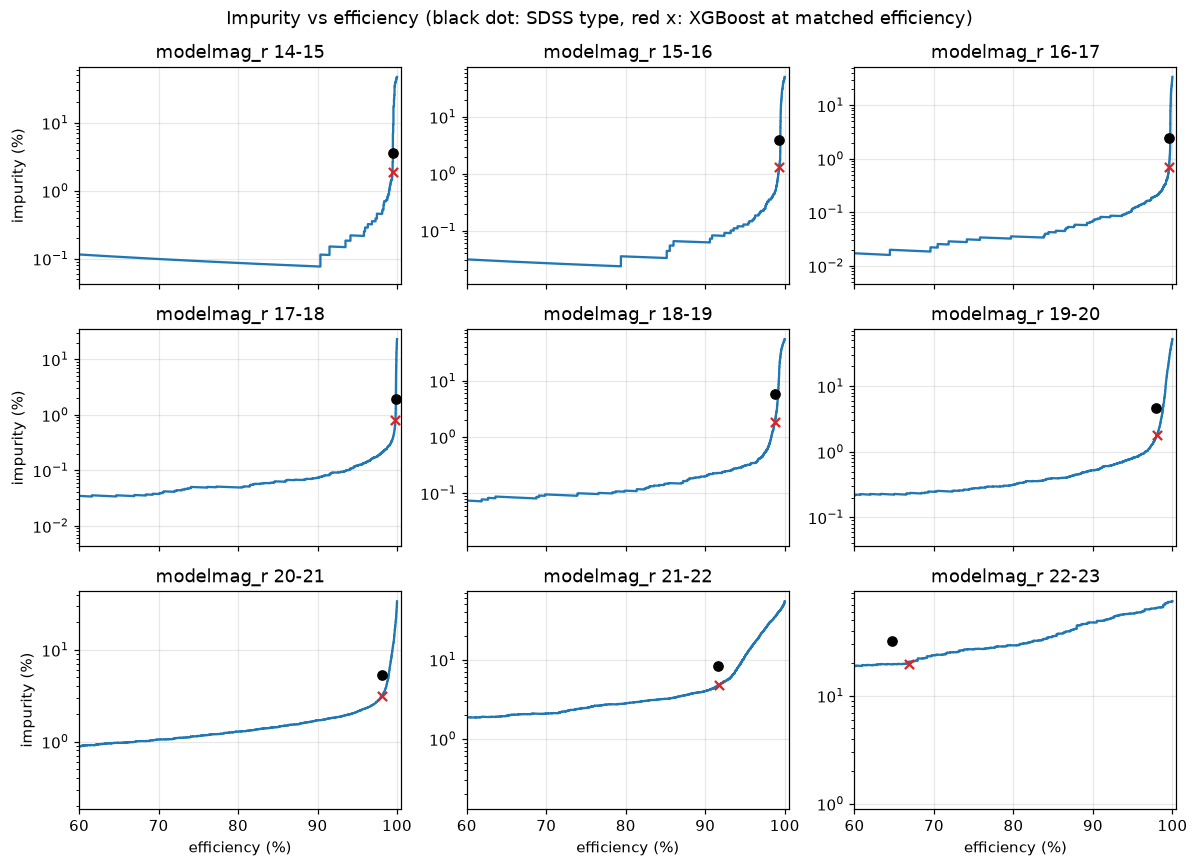

In [19]:
fig, axes = plt.subplots(3, 3, figsize=(11, 8), sharex=True)
for b, ax in enumerate(axes.ravel()):
    in_bin = bins_test == b
    precision, recall, _ = precision_recall_curve(gal_test[in_bin], score_test[in_bin])
    ax.plot(100 * recall, 100 * (1 - precision), color="C0")
    ax.scatter(
        result_a["type eff %"].iloc[b], result_a["type imp %"].iloc[b], color="black", zorder=3
    )
    ax.scatter(
        result_a["xgb eff %"].iloc[b],
        result_a["xgb imp %"].iloc[b],
        color="C3",
        marker="x",
        zorder=3,
    )
    ax.set(yscale="log", title=f"modelmag_r {BIN_LABELS[b]}", xlim=(60, 100.5))
for ax in axes[-1]:
    ax.set_xlabel("efficiency (%)")
for ax in axes[:, 0]:
    ax.set_ylabel("impurity (%)")
fig.suptitle("Impurity vs efficiency (black dot: SDSS type, red x: XGBoost at matched efficiency)")
plt.tight_layout()
plt.savefig(OUT / "figures" / "impurity_efficiency_curves.png")
plt.show()

## 21. Second target: how many galaxies at 1% impurity?

Cosmology studies usually state how much contamination they can tolerate. Operating point B asks: *keeping impurity at or below 1%, how many galaxies can we keep?* We apply the frozen thresholds from section 17 to the test set. A missing value means that no threshold in that bin reached 1% impurity on the validation set.

In [20]:
selected_b = select(score_test, thresholds_b, bins_test)
table_b = joint_counts(selected_b, type_selected_test)
xgb_eff_b, xgb_imp_b = rates(table_b, XGB_SEL)
type_eff_b, type_imp_b = rates(table_b, TYPE_SEL)

result_b = pd.DataFrame(
    {
        "xgb eff %": xgb_eff_b,
        "xgb imp %": xgb_imp_b,
        "type eff %": type_eff_b,
        "type imp %": type_imp_b,
    },
    index=BIN_LABELS,
)
result_b.to_csv(OUT / "results" / "test_impurity_cap.csv")
display(result_b.round(2))

/tmp/ipykernel_280389/763182224.py:15: RuntimeWarning: invalid value encountered in divide
  impurity = 100 * (selected - galaxies_kept) / selected


,xgb eff %,xgb imp %,type eff %,type imp %
14-15,99.20,1.28,99.45,3.60
15-16,99.20,1.00,99.30,3.85
16-17,99.64,1.00,99.58,2.46
17-18,99.83,1.03,99.82,1.90
18-19,98.41,1.15,98.79,5.77
19-20,96.03,0.90,97.93,4.61
20-21,64.13,0.96,98.08,5.28
21-22,30.51,1.11,91.61,8.40
22-23,0.00,NaN,64.66,32.18


## 22. Quasar check

Our main convention counts quasars as contaminants. Here we split the contamination into stars and quasars, and recompute impurity with quasars left out of the test set. If the two impurity columns were close, the quasar choice would not matter. They are not close, so quasars are a large part of the contamination and both versions should be reported. The last column of each group shows the share of contaminants that are quasars.

In [21]:
def contamination_breakdown(selected):
    counts = selection_counts(meta_test, selected)["selected"]
    contaminants = counts["STAR"] + counts["QSO"]
    return pd.DataFrame(
        {
            "impurity (stars+QSO) %": 100 * contaminants / counts.sum(axis=1),
            "impurity (stars only) %": 100 * counts["STAR"] / (counts["STAR"] + counts["GALAXY"]),
            "QSO share of contaminants %": 100 * counts["QSO"] / contaminants,
        }
    )


qso_check = pd.concat(
    {
        "XGBoost": contamination_breakdown(selected_a),
        "SDSS type": contamination_breakdown(type_selected_test),
    },
    axis=1,
)
qso_check.index = BIN_LABELS
qso_check.to_csv(OUT / "results" / "qso_sensitivity.csv")
display(qso_check.round(2))

XGBoost                          \
      impurity (stars+QSO) % impurity (stars only) %   
14-15                   1.88                    1.04   
15-16                   1.30                    0.55   
16-17                   0.71                    0.25   
17-18                   0.81                    0.25   
18-19                   1.83                    0.57   
19-20                   1.78                    0.60   
20-21                   3.16                    1.09   
21-22                   4.78                    1.81   
22-23                  19.81                    8.75   

                                               SDSS type  \
      QSO share of contaminants % impurity (stars+QSO) %   
14-15                       45.45                   3.60   
15-16                       57.55                   3.85   
16-17                       64.36                   2.46   
17-18                       68.91                   1.90   
18-19                       69.34                   5.77   
19-20                       66.67                   4.61   
20-21                       66.12                   5.28   
21-22                       63.31                   8.40   
22-23                       61.18                  32.18   

                                                           
      impurity (stars only) % QSO share of contaminants %  
14-15                    2.68                       26.17  
15-16                    2.89                       25.71  
16-17                    1.65                       33.40  
17-18                    1.01                       47.22  
18-19                    1.72                       71.38  
19-20                    2.36                       49.93  
20-21                    2.94                       45.68  
21-22                    4.93                       43.51  
22-23                   17.57                       55.06

## 23. What is the model using?

To see which features drive the model's decisions, we use **SHAP values**. They split each prediction into contributions from individual features, and the average absolute contribution tells us which features matter most. XGBoost computes them directly with `pred_contribs=True`. We use a random sample of 20,000 validation objects to keep this fast. If one surprising feature dominated, that would be worth investigating for leakage (a feature that secretly contains the answer).

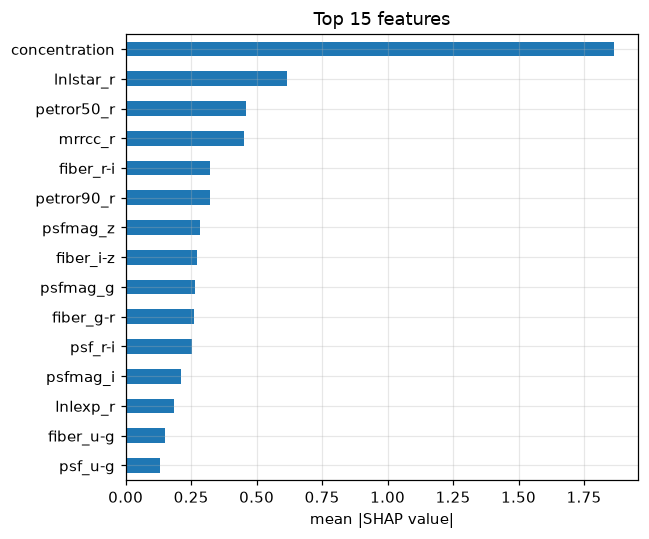

In [22]:
sample = X_val.sample(20_000, random_state=SEED)
contributions = final_model.get_booster().predict(
    xgb.DMatrix(sample), pred_contribs=True, iteration_range=(0, final_model.best_iteration + 1)
)
importance = pd.Series(np.abs(contributions[:, :-1]).mean(axis=0), index=FEATURES).sort_values()

fig, ax = plt.subplots(figsize=(6, 5))
importance.tail(15).plot.barh(ax=ax, color="C0")
ax.set(xlabel="mean |SHAP value|", title="Top 15 features")
plt.tight_layout()
plt.savefig(OUT / "figures" / "feature_importance.png")
plt.show()

## 24. Which kinds of information matter?

We retrain the model using only some feature groups and compare each version with the full model, to see how much each kind of information adds. Everything here uses the validation set, because this is a development study, and the test set stays untouched. Black dots are the SDSS `type` rule.

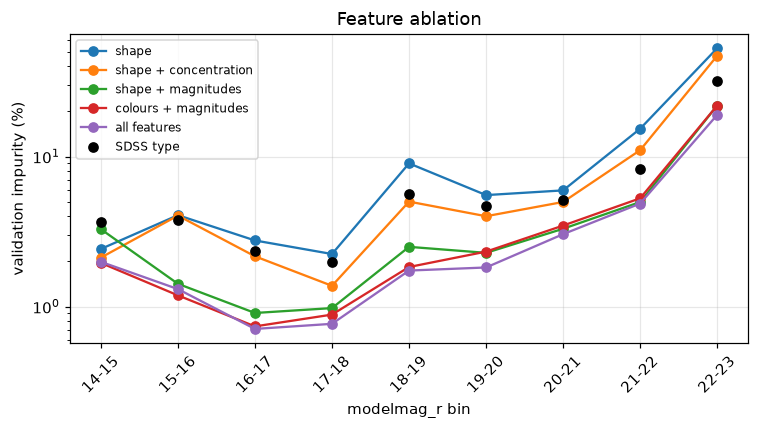

,typical impurity (%)
shape,6.249
shape + concentration,4.783
shape + magnitudes,2.729
colours + magnitudes,2.392
all features,2.208


In [23]:
def plot_impurity_by_bin(ax, curves, baseline):
    x = np.arange(N_BINS)
    for label, values in curves.items():
        ax.plot(x, values, marker="o", label=label)
    ax.scatter(x, baseline, color="black", zorder=3, label="SDSS type")
    ax.set(yscale="log", xlabel="modelmag_r bin", ylabel="validation impurity (%)")
    ax.set_xticks(x, BIN_LABELS, rotation=45)
    ax.legend(fontsize=8)


groups = FEATURE_GROUPS
arms = {
    "shape": groups["shape"],
    "shape + concentration": groups["shape"] + groups["concentration"],
    "shape + magnitudes": groups["shape"] + groups["magnitudes"],
    "colours + magnitudes": groups["colours"] + groups["magnitudes"],
    "all features": FEATURES,
}
ablation = {
    name: fit_and_score(best_params, train_idx, columns=cols)[1] for name, cols in arms.items()
}

fig, ax = plt.subplots(figsize=(7, 4))
plot_impurity_by_bin(ax, ablation, baselines_val["SDSS type"]["impurity"].to_numpy())
ax.set_title("Feature ablation")
plt.tight_layout()
plt.savefig(OUT / "figures" / "feature_ablation.png")
plt.show()

pd.Series({k: typical_impurity(v) for k, v in ablation.items()}, name="typical impurity (%)").round(
    3
).to_frame()

## 25. How much labelled data do we need?

Spectra are expensive, so real surveys often have few labelled objects. We train on random subsets of growing size (from 1,000 objects up to the full training set) and watch the impurity. When the curve flattens, more labels no longer help. The dashed line is SDSS `type`, so the point where the curve crosses it shows how few labels are enough to beat the standard rule.

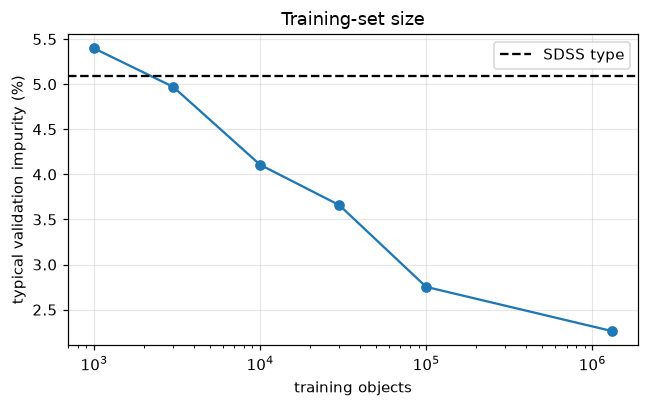

In [24]:
sizes = [1_000, 3_000, 10_000, 30_000, 100_000, len(train_idx)]
rng = np.random.default_rng(SEED)
size_results = {
    n: typical_impurity(fit_and_score(best_params, rng.choice(train_idx, n, replace=False))[1])
    for n in sizes
}

fig, ax = plt.subplots(figsize=(6, 3.8))
ax.plot(list(size_results), list(size_results.values()), marker="o")
ax.axhline(
    typical_impurity(baselines_val["SDSS type"]["impurity"].to_numpy()),
    color="black",
    ls="--",
    label="SDSS type",
)
ax.set(
    xscale="log",
    xlabel="training objects",
    ylabel="typical validation impurity (%)",
    title="Training-set size",
)
ax.legend()
plt.tight_layout()
plt.savefig(OUT / "figures" / "training_size.png")
plt.show()

## 26. What if the training data is shallow?

New surveys often have spectra only for their brighter objects. We train using only objects brighter than a limit (19.5, 20.5 or 21.5), then score on **all** brightness bins. Note that the *training* set is limited and the scoring set is not. The result shows how well a model trained on bright objects copes with faint ones.

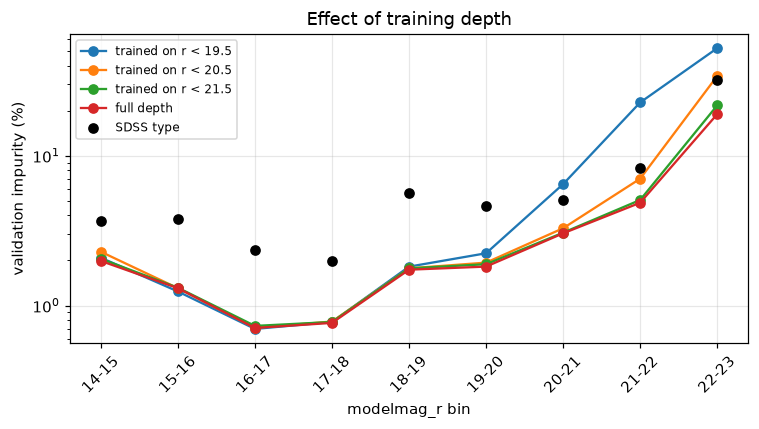

In [25]:
depth_curves = {}
for limit in (19.5, 20.5, 21.5, None):
    rows = (
        train_idx
        if limit is None
        else train_idx[(raw.loc[train_idx, "modelmag_r"] < limit).to_numpy()]
    )
    label = "full depth" if limit is None else f"trained on r < {limit}"
    depth_curves[label] = fit_and_score(best_params, rows)[1]

fig, ax = plt.subplots(figsize=(7, 4))
plot_impurity_by_bin(ax, depth_curves, baselines_val["SDSS type"]["impurity"].to_numpy())
ax.set_title("Effect of training depth")
plt.tight_layout()
plt.savefig(OUT / "figures" / "training_depth.png")
plt.show()

## 27. Are the probabilities trustworthy?

If the model says "80% galaxy", then about 80% of such objects should truly be galaxies. We check this with a calibration curve, drawn for bright, middle and faint objects. A curve near the diagonal means well calibrated. This matters if the probabilities will be used directly, for example as weights, instead of a hard cut-off. Our main results use thresholds, so they do not depend on it.

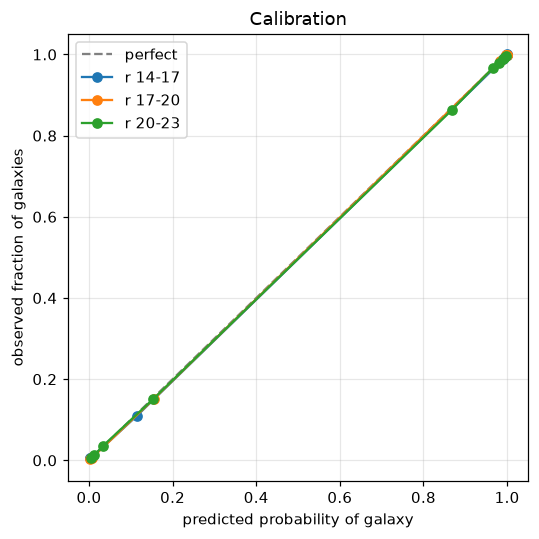

In [26]:
probability_test = final_model.predict_proba(X_test)[:, 1]
ranges = {"r 14-17": (14, 17), "r 17-20": (17, 20), "r 20-23": (20, 23)}

fig, ax = plt.subplots(figsize=(5, 5))
ax.plot([0, 1], [0, 1], ls="--", color="gray", label="perfect")
for label, (lo, hi) in ranges.items():
    in_range = ((meta_test["modelmag_r"] >= lo) & (meta_test["modelmag_r"] < hi)).to_numpy()
    observed, predicted = calibration_curve(
        y_test[in_range], probability_test[in_range], n_bins=10, strategy="quantile"
    )
    ax.plot(predicted, observed, marker="o", label=label)
ax.set(
    xlabel="predicted probability of galaxy",
    ylabel="observed fraction of galaxies",
    title="Calibration",
)
ax.legend()
plt.tight_layout()
plt.savefig(OUT / "figures" / "calibration.png")
plt.show()

## 28. Headline summary

One table with the numbers to report: overall impurity of XGBoost and SDSS `type` at matched efficiency, with the bootstrap interval. It is also saved to `outputs/results/headline.csv`.

In [27]:
overall = result_a.loc["all bins"]
ratio_text = (
    f"{overall['type/xgb ratio']:.2f} ({overall['ratio low']:.2f} to {overall['ratio high']:.2f})"
)
headline = pd.Series(
    {
        "efficiency, SDSS type (%)": overall["type eff %"],
        "efficiency, XGBoost (%)": overall["xgb eff %"],
        "impurity, SDSS type (%)": overall["type imp %"],
        "impurity, XGBoost (%)": overall["xgb imp %"],
        "impurity 68% interval": f"{overall['xgb imp low']:.2f} to {overall['xgb imp high']:.2f}",
        "impurity ratio type / XGBoost": ratio_text,
    },
    name="test set, all bins",
)
headline.to_frame().to_csv(OUT / "results" / "headline.csv")
display(headline.to_frame())

,"test set, all bins"
"efficiency, SDSS type (%)",98.602206
"efficiency, XGBoost (%)",98.625359
"impurity, SDSS type (%)",3.841097
"impurity, XGBoost (%)",1.739752
impurity 68% interval,1.71 to 1.76
impurity ratio type / XGBoost,2.21 (2.18 to 2.23)


## 29. Limitations

These are the points that could make the results look better than they would be in practice:
- **The labelled sample is not a fair sample of the sky.** Only objects that were given a spectrum have a trusted label, and spectra were taken for *targeted* objects. The sharp peaks in the brightness histogram (section 4) suggest this. Performance on faint objects may be optimistic for the full photometric catalog. Correcting for this would need counts from the full photometric catalog, which this file does not contain.
- **Overall numbers depend on the brightness mix of this particular sample**, so the per-bin numbers are the more meaningful ones.
- **The brightest and faintest bins have the fewest objects**, so their error bars are the widest.
- **Bootstrap intervals** treat the frozen thresholds as fixed.
- **The quasar convention** (section 2) changes the numbers. Section 22 shows by how much.

## References

- XGBoost scikit-learn API (early stopping, `device`, `tree_method`): https://xgboost.readthedocs.io/en/stable/python/sklearn_estimator.html
- XGBoost parameters: https://xgboost.readthedocs.io/en/stable/parameter.html
- XGBoost prediction and SHAP (`pred_contribs`): https://xgboost.readthedocs.io/en/stable/prediction.html
- scikit-learn `ParameterSampler`, `precision_recall_curve`, `calibration_curve`: https://scikit-learn.org/stable/api/index.html
- Data: SDSS DR9 catalog, shared on Hugging Face at https://huggingface.co/datasets/nevilcp/sdss-dr9-star-galaxy
- Sevilla-Noarbe & Etayo-Sotos (2015), arXiv:1504.06776, the problem definition and the SDSS `type` comparison.